<a href="https://colab.research.google.com/github/PlayWorawit/Fundamentals-of-Deep-Learning/blob/main/notebooks/DEEPLEARN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1 · Setup, GPU check & the spine


In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# --- reproducibility: fix the seed so your reported numbers reproduce -------
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- device: train on the GPU if Colab gave you one -------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then re-run.")


@torch.no_grad()
def accuracy(logits, y):
    """Fraction correct for a batch of class logits vs integer labels."""
    return (logits.argmax(dim=-1) == y).float().mean().item()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    """One no-grad pass over `loader`; returns (mean loss, accuracy)."""
    model.eval()                                  # dropout off, BN uses running stats
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)         # same device as the model
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=-1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(model, train_loader, val_loader, *, epochs=10, lr=1e-3,
          weight_decay=0.0, loss_fn=None, max_grad_norm=None):
    """The five-step loop (forward, loss, zero_grad, backward, step) with a
    validation pass each epoch. Returns a per-epoch history dict."""
    model = model.to(device)                      # move the model once, before the loop
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:                 # the five steps, per batch
            x, y = x.to(device), y.to(device)     # data on the SAME device as the model
            logits = model(x)                     # 1. forward
            loss = loss_fn(logits, y)             # 2. loss
            optimizer.zero_grad()                 # 3. clear last batch's grads
            loss.backward()                       # 4. backprop
            if max_grad_norm is not None:         # clip for RNNs/LSTMs (Track B)
                nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()                      # 5. update the weights

        tr_loss, tr_acc = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        print(f"epoch {epoch + 1:2d}/{epochs}  "
              f"train_loss={tr_loss:.3f} acc={tr_acc:.2%}  |  "
              f"val_loss={va_loss:.3f} acc={va_acc:.2%}")
    return history


def plot_curves(history):
    """Train vs. validation loss and accuracy — read the gap (labs L5/L11)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], "-o", label="train")
    ax1.plot(epochs, history["val_loss"], "-o", label="val")
    ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history["train_acc"], "-o", label="train")
    ax2.plot(epochs, history["val_acc"], "-o", label="val")
    ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


print("spine ready: accuracy(), evaluate(), train(), plot_curves()")

device: cuda
spine ready: accuracy(), evaluate(), train(), plot_curves()


## 2 · Load Dataset


In [2]:
# ============================================================================
# TRACK A · VISION — CIFAR-10 (real 32x32 colour photos, 10 classes)
# Build a CNN. This block is ACTIVE so the notebook runs end-to-end out of the
# box; comment it out if you pick Track B or C.
# ============================================================================
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

# What's real/messy: natural photos with backgrounds, lighting, and pose
# variation. Some classes look alike (cat vs dog, automobile vs truck) -- your
# confusion matrix later will show exactly which.
norm = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
train_tf = transforms.Compose([                 # augment ONLY the training set
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(), norm,
])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])   # never augment val/test

# CIFAR's official split is 50k train + 10k test. We hold the 10k test out
# untouched, and carve a validation set off the training data.
full_train = datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=eval_tf)

# Subset to train fast on a T4 (~3-4 min). Use all 50k for a stronger result.
SUBSET = 10000
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(full_train), generator=g)[:SUBSET].tolist()
n_val = SUBSET // 5
train_idx, val_idx = idx[n_val:], idx[:n_val]
train_set = Subset(full_train, train_idx)
# val must NOT be augmented -> point it at a non-augmented copy of the data
val_base = datasets.CIFAR10("./data", train=True, download=True, transform=eval_tf)
val_set = Subset(val_base, val_idx)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)
classes = full_train.classes                    # ['airplane', 'automobile', ...]
print(f"train={len(train_set)} val={len(val_set)} test={len(test_set)} "
      f"classes={len(classes)}")

100%|██████████| 170M/170M [26:06<00:00, 109kB/s]


train=8000 val=2000 test=10000 classes=10


## 3 · Look at the data




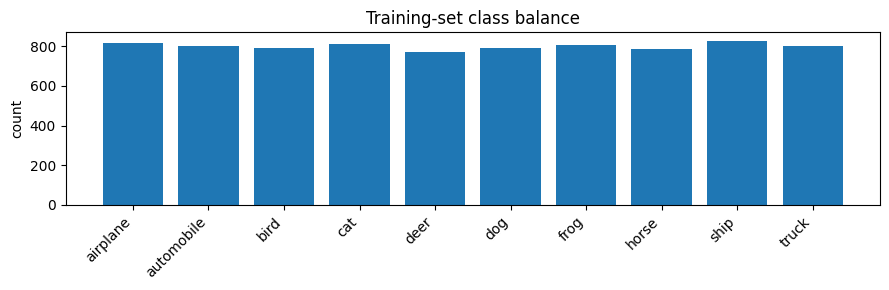

majority-class baseline (train): 10.4%


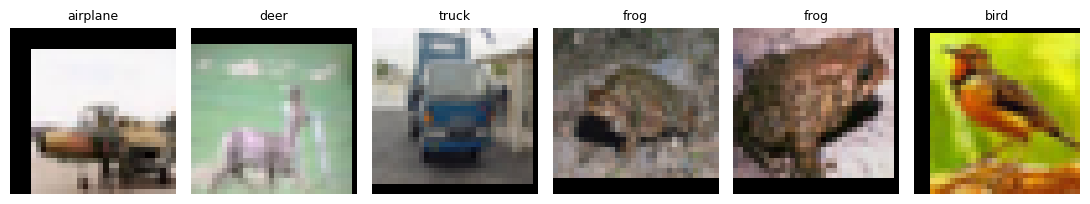

In [3]:
# EDA for the ACTIVE track (A · CIFAR-10). Adapt for B (print sample names per
# class) or C (df.head(), df["species"].value_counts(), a pairplot).
import collections

# 1. Class histogram of the training split -- is it balanced?
counts = collections.Counter(int(train_set[i][1]) for i in range(len(train_set)))
plt.figure(figsize=(9, 3))
plt.bar([classes[k] for k in sorted(counts)], [counts[k] for k in sorted(counts)])
plt.xticks(rotation=45, ha="right"); plt.ylabel("count")
plt.title("Training-set class balance"); plt.tight_layout(); plt.show()
print("majority-class baseline (train):",
      f"{max(counts.values()) / sum(counts.values()):.1%}")

# 2. A few sample images with their labels.
inv = transforms.Normalize((-0.4914 / 0.2470, -0.4822 / 0.2435, -0.4465 / 0.2616),
                            (1 / 0.2470, 1 / 0.2435, 1 / 0.2616))
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for ax, i in zip(axes, range(6)):
    img, label = train_set[i]
    ax.imshow(inv(img).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(classes[label], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

##  4 · Build Model





In [4]:
import torch
import torch.nn as nn

class ImprovedCNN(nn.Module):
    def __init__(self, n_classes=10, p_drop=0.3):
        super().__init__()

        # Block 1: 32x32 -> 16x16
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1)
        )

        # Block 2: 16x16 -> 8x8
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.2)
        )

        # Block 3: 8x8 -> 4x4
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25)
        )

        # Classifier Head: 128 x 4 x 4 = 2048
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.head(x)

# สร้าง instance ของโมเดล
model = ImprovedCNN(n_classes=len(classes))

##  5 · Train





In [5]:
history = train(
    model,
    train_loader,
    val_loader,
    epochs=30,
    lr=5e-4,
    weight_decay=1e-4,
)

epoch  1/30  train_loss=1.692 acc=37.00%  |  val_loss=1.643 acc=38.45%
epoch  2/30  train_loss=1.540 acc=41.86%  |  val_loss=1.516 acc=43.60%
epoch  3/30  train_loss=1.443 acc=46.83%  |  val_loss=1.440 acc=46.00%
epoch  4/30  train_loss=1.395 acc=48.36%  |  val_loss=1.381 acc=46.45%
epoch  5/30  train_loss=1.343 acc=51.04%  |  val_loss=1.328 acc=51.65%
epoch  6/30  train_loss=1.282 acc=52.84%  |  val_loss=1.294 acc=51.90%
epoch  7/30  train_loss=1.256 acc=54.55%  |  val_loss=1.240 acc=54.05%
epoch  8/30  train_loss=1.196 acc=56.03%  |  val_loss=1.189 acc=56.85%
epoch  9/30  train_loss=1.170 acc=57.40%  |  val_loss=1.170 acc=55.55%
epoch 10/30  train_loss=1.116 acc=59.80%  |  val_loss=1.111 acc=58.25%
epoch 11/30  train_loss=1.088 acc=60.82%  |  val_loss=1.077 acc=60.20%
epoch 12/30  train_loss=1.076 acc=60.77%  |  val_loss=1.070 acc=59.75%
epoch 13/30  train_loss=1.026 acc=63.01%  |  val_loss=1.027 acc=62.50%
epoch 14/30  train_loss=1.013 acc=63.62%  |  val_loss=1.026 acc=63.20%
epoch 

## 6 · Evaluate, experiment & reflect

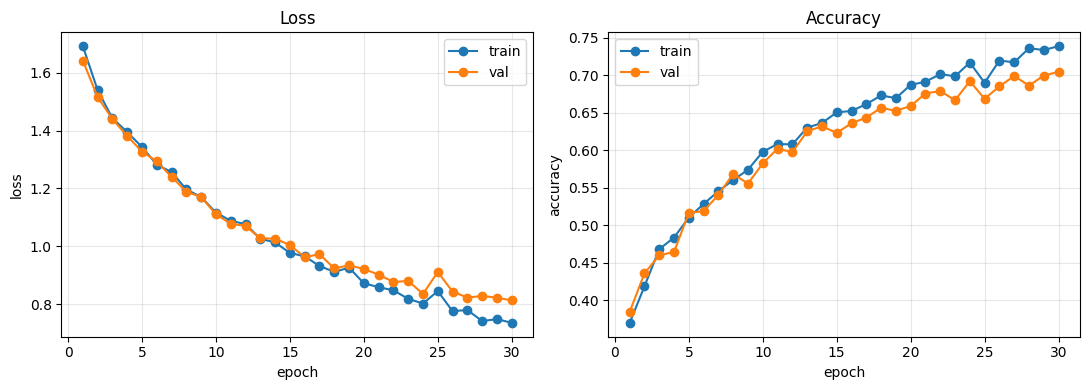

In [6]:
plot_curves(history)

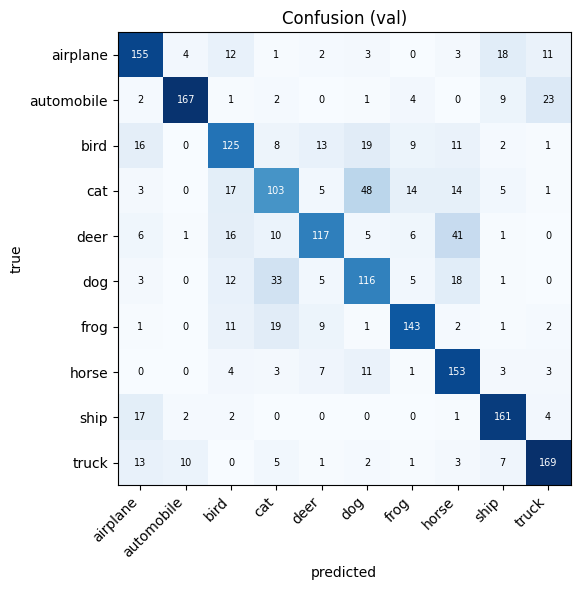

  recall  cat          49.05%
  recall  deer         57.64%
  recall  dog          60.10%
  recall  bird         61.27%
  recall  airplane     74.16%
  recall  frog         75.66%
  recall  automobile   79.90%
  recall  truck        80.09%
  recall  horse        82.70%
  recall  ship         86.10%


In [7]:
@torch.no_grad()
def confusion_matrix(model, loader, n_classes):
    model.eval()
    cm = torch.zeros(n_classes, n_classes, dtype=torch.long)
    for x, y in loader:
        preds = model(x.to(device)).argmax(dim=-1).cpu()
        for t, p in zip(y, preds):
            cm[t, p] += 1
    return cm

cm = confusion_matrix(model, val_loader, len(classes))
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion (val)")
for i in range(len(classes)):                    # annotate counts
    for j in range(len(classes)):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.tight_layout(); plt.show()

# Per-class recall (of the true class c, what fraction did we catch?)
recall = cm.diag() / cm.sum(dim=1).clamp(min=1)
for c, r in sorted(zip(classes, recall.tolist()), key=lambda t: t[1]):
    print(f"  recall  {c:<12} {r:.2%}")

## 7 · Test



In [8]:
# ✅ ONE-SHOT held-out test evaluation. Do NOT tune after seeing this number.
test_loss, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss())
majority = max(
    collections.Counter(int(test_set[i][1]) for i in range(len(test_set))).values()
) / len(test_set)
print(f"majority-class baseline (test): {majority:.2%}")
print(f"FINAL TEST  loss={test_loss:.3f}  accuracy={test_acc:.2%}")
print("beat baseline:", "YES" if test_acc > majority else "no -- keep iterating")

majority-class baseline (test): 10.00%
FINAL TEST  loss=0.788  accuracy=72.26%
beat baseline: YES
